# Exercise 2: Multilayer ANN

In [505]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import matplotlib.pyplot as plt

## Data Preparation

In [507]:
# Loading training and testing data
train_df = pd.read_json("hepatitis_training_data.json")
test_df = pd.read_json("hepatitis_testing_data.json")

In [508]:
# Check the data head and shape
train_df.head()

,Age,Sex,Steroid,Antivirals,Fatigue,Malaise,Anorexia,Liver_big,Liver_firm,Spleen_palpable,Spiders,Ascites,Varices,Bilurubin,Alk_phosphate,Sgot,Albumin,Protime,Histology,Die_Live
0,30,2,1,2,2,2,2,1,2,2,2,2,2,1.0,85,18,4.0,62,1,2
1,50,1,1,2,1,2,2,1,2,2,2,2,2,0.9,135,42,3.5,62,1,2
2,78,1,2,2,1,2,2,2,2,2,2,2,2,0.7,96,32,4.0,62,1,2
3,31,1,2,1,2,2,2,2,2,2,2,2,2,0.7,46,52,4.0,80,1,2
4,34,1,2,2,2,2,2,2,2,2,2,2,2,1.0,105,200,4.0,62,1,2


In [509]:
test_df.head()

,Age,Sex,Steroid,Antivirals,Fatigue,Malaise,Anorexia,Liver_big,Liver_firm,Spleen_palpable,Spiders,Ascites,Varices,Bilurubin,Alk_phosphate,Sgot,Albumin,Protime,Histology,Die_Live
0,61,1,1,2,1,1,2,1,1,2,1,2,2,0.8,75,20,4.1,62,2,2
1,53,2,1,2,1,2,2,2,2,1,1,2,1,1.5,81,19,4.1,48,2,2
2,43,1,2,2,1,2,2,2,2,1,1,1,2,1.2,100,19,3.1,42,2,1


In [510]:
print("Training data shape",train_df.shape, "\nTest data shape", test_df.shape)

Training data shape (152, 20) 
Test data shape (3, 20)


In [511]:
# Show total missing values per column
print("Missing values in training data:\n", train_df.isnull().sum())
print("\nMissing values in testing data:\n", test_df.isnull().sum())

Missing values in training data:
 Age                0
Sex                0
Steroid            0
Antivirals         0
Fatigue            0
Malaise            0
Anorexia           0
Liver_big          0
Liver_firm         0
Spleen_palpable    0
Spiders            0
Ascites            0
Varices            0
Bilurubin          0
Alk_phosphate      0
Sgot               0
Albumin            0
Protime            0
Histology          0
Die_Live           0
dtype: int64

Missing values in testing data:
 Age                0
Sex                0
Steroid            0
Antivirals         0
Fatigue            0
Malaise            0
Anorexia           0
Liver_big          0
Liver_firm         0
Spleen_palpable    0
Spiders            0
Ascites            0
Varices            0
Bilurubin          0
Alk_phosphate      0
Sgot               0
Albumin            0
Protime            0
Histology          0
Die_Live           0
dtype: int64


In [512]:
# Separate features (X) and labels (y)
X_train = train_df.drop(columns=["Die_Live"]).values
X_test = test_df.drop(columns=["Die_Live"]).values
y_train_raw = train_df[["Die_Live"]]
y_test_raw = test_df[["Die_Live"]]

In [513]:
# Replace missing values in features with column mean
imputer = SimpleImputer(strategy="mean")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [514]:
# Normalize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [515]:
# Apply one-hot encoding to target
encoder = OneHotEncoder(sparse_output=False)
y_train = encoder.fit_transform(y_train_raw)
y_test = encoder.transform(y_test_raw)

In [516]:
# Check data training and test
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("\nFirst 10 encoded labels in training data:\n", y_train[:10])

X_train shape: (152, 19)
y_train shape: (152, 2)
X_test shape: (3, 19)
y_test shape: (3, 2)

First 10 encoded labels in training data:
 [[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]


## Multi Layer ANN Architecture

In [518]:
# Set hyperparameter
def set_hyperparameters():
    return {
        "epochs": 2000,
        "lr": 0.5,
        "seed": 42
    }

In [519]:
# Initialize weights and biases
def initialize_weights(input_size=19, h1=30, h2=15, output_size=2, seed=42):
    np.random.seed(seed)
    W1 = np.random.randn(h1, input_size) * 0.01
    b1 = np.zeros((h1, 1))
    W2 = np.random.randn(h2, h1) * 0.01
    b2 = np.zeros((h2, 1))
    W3 = np.random.randn(output_size, h2) * 0.01
    b3 = np.zeros((output_size, 1))
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2, "W3": W3, "b3": b3}

In [520]:
# Activation Functions: Sigmoid function and derivative
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    return a * (1 - a)

In [521]:
# Forward propagation
def forward_propagation(X, params):
    Z1 = np.dot(params["W1"], X.T) + params["b1"]
    A1 = sigmoid(Z1)
    Z2 = np.dot(params["W2"], A1) + params["b2"]
    A2 = sigmoid(Z2)
    Z3 = np.dot(params["W3"], A2) + params["b3"]
    A3 = sigmoid(Z3)
    cache = {"A1": A1, "A2": A2, "A3": A3}
    return A3, cache

In [522]:
# Compute loss function
def compute_loss_mse(A3, Y):
    m = Y.shape[0]
    return (1/(2*m)) * np.sum((A3 - Y.T) ** 2)

In [523]:
# Backward propagation
def backward_propagation_mse(X, Y, params, cache):
    m = X.shape[0]
    A1, A2, A3 = cache["A1"], cache["A2"], cache["A3"]

    # Output layer (MSE derivative)
    dZ3 = (A3 - Y.T) * sigmoid_derivative(A3)
    dW3 = (1/m) * np.dot(dZ3, A2.T)
    db3 = (1/m) * np.sum(dZ3, axis=1, keepdims=True)

    # Hidden layer 2
    dZ2 = np.dot(params["W3"].T, dZ3) * sigmoid_derivative(A2)
    dW2 = (1/m) * np.dot(dZ2, A1.T)
    db2 = (1/m) * np.sum(dZ2, axis=1, keepdims=True)

    # Hidden layer 1
    dZ1 = np.dot(params["W2"].T, dZ2) * sigmoid_derivative(A1)
    dW1 = (1/m) * np.dot(dZ1, X)
    db1 = (1/m) * np.sum(dZ1, axis=1, keepdims=True)

    return {"dW1": dW1, "db1": db1,
            "dW2": dW2, "db2": db2,
            "dW3": dW3, "db3": db3}

In [524]:
# Update weights
def update_weights(params, grads, lr):
    for l in range(1, 4):
        params[f"W{l}"] -= lr * grads[f"dW{l}"]
        params[f"b{l}"] -= lr * grads[f"db{l}"]
    return params

## Train Model

In [526]:
# Training loop
def train_model_mse(X, Y, hyperparams):
    params = initialize_weights(seed=hyperparams["seed"])
    
    # Initial activations
    A3_init, cache_init = forward_propagation(X, params)
    print("\n=== Initial Activations (first 5 samples) ===")
    print("Layer 1:", cache_init["A1"][:, :5])
    print("\nLayer 2:", cache_init["A2"][:, :5])
    print("\nOutput:", cache_init["A3"][:, :5])
    
    losses = []
    for i in range(hyperparams["epochs"]):
        A3, cache = forward_propagation(X, params)
        loss = compute_loss_mse(A3, Y)
        grads = backward_propagation_mse(X, Y, params, cache)
        params = update_weights(params, grads, hyperparams["lr"])
        losses.append(loss)
        if i % 100 == 0:
            print(f"Epoch {i}, MSE Loss: {loss:.4f}")
    return params, losses

In [527]:
# Prediction
def predict(X, params):
    A3, cache = forward_propagation(X, params)
    return np.argmax(A3, axis=0), cache

## Model Results and Evaluation

In [529]:
# Run training model
hyperparams = set_hyperparameters()
params, losses = train_model(X_train, y_train, hyperparams)


=== Initial Activations (first 5 samples) ===
Layer 1 (30 neurons):
[[0.4988898  0.50070136 0.51449576 0.50329997 0.50420724]
 [0.5193356  0.50904982 0.49164035 0.50085119 0.50000087]
 [0.5059989  0.4962345  0.49105247 0.50634925 0.50446166]
 [0.49258473 0.4903992  0.49892703 0.49314512 0.50147639]
 [0.49712409 0.50335702 0.49863685 0.50972603 0.50168679]
 [0.50151943 0.49291215 0.48421758 0.49597577 0.48688764]
 [0.51905814 0.51298298 0.50253108 0.51794073 0.50749694]
 [0.48779867 0.49554825 0.51124324 0.51497121 0.50645846]
 [0.50149055 0.49098063 0.49021687 0.50814056 0.51558975]
 [0.51277661 0.50827261 0.50191762 0.50814096 0.51585749]
 [0.50737861 0.4919169  0.4952912  0.51343905 0.49567151]
 [0.50588572 0.5061058  0.533427   0.49836994 0.50040717]
 [0.49994704 0.49554855 0.48855615 0.49228781 0.49936141]
 [0.53946355 0.51724613 0.50455778 0.52178996 0.49911579]
 [0.48411074 0.49271349 0.50266757 0.49079381 0.49879187]
 [0.50264489 0.50145738 0.48687842 0.49983518 0.49767456]
 [0

In [530]:
# Model Evaluation
train_preds, cache_train = predict(X_train, params)
test_preds, _ = predict(X_test, params)

y_train_labels = np.argmax(y_train, axis=1)
y_test_labels = np.argmax(y_test, axis=1)

train_acc = np.mean(train_preds == y_train_labels) * 100
test_acc = np.mean(test_preds == y_test_labels) * 100

print(f"\nTrain Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")


Train Accuracy: 99.34%
Test Accuracy: 100.00%


In [531]:
# Final activations after training
print("\n=== Activations after training (first 5 samples) ===")
print("Layer 1 (30 neurons):")
print(cache_train["A1"][:, :5])
print("\nLayer 2 (15 neurons):")
print(cache_train["A2"][:, :5])
print("\nFinal Output Layer (2 neurons):")
print(cache_train["A3"][:, :5])


=== Activations after training (first 5 samples) ===
Layer 1 (30 neurons):
[[0.62304132 0.41770938 0.25521622 0.29686264 0.56031565]
 [0.62891364 0.5781221  0.56968445 0.67871957 0.59949395]
 [0.45035899 0.64484621 0.81083917 0.78821586 0.59252797]
 [0.69647491 0.44779095 0.19010718 0.34666706 0.61465459]
 [0.71361728 0.44264487 0.17483221 0.32498619 0.59897997]
 [0.94235451 0.55661844 0.39826248 0.83767669 0.55370665]
 [0.97239694 0.53894323 0.71877493 0.98950645 0.82284452]
 [0.99486362 0.33997581 0.72726003 0.99986013 0.96086351]
 [0.01512835 0.68591046 0.95705111 0.56616356 0.57487123]
 [0.99151674 0.50504794 0.16395895 0.98023516 0.92346585]
 [0.98872376 0.43841383 0.71451717 0.99841134 0.93654019]
 [0.91589895 0.55446455 0.57765774 0.88443212 0.53936777]
 [0.94146175 0.56773929 0.59852179 0.92792235 0.52895129]
 [0.98552305 0.48657183 0.75935441 0.99727949 0.89086633]
 [0.71859452 0.39870649 0.16913133 0.27014719 0.58002693]
 [0.84282407 0.4517346  0.07937759 0.34715325 0.662686

In [532]:
# Predicted vs Actual
print("\n=== Predicted vs Actual (first 10 samples) ===")
for i in range(10):
    print(f"Pred: {np.round(cache_train['A3'][:, i], 3)}  Actual: {y_train[i]}")


=== Predicted vs Actual (first 10 samples) ===
Pred: [0.012 0.988]  Actual: [0. 1.]
Pred: [0.015 0.985]  Actual: [0. 1.]
Pred: [0.016 0.984]  Actual: [0. 1.]
Pred: [0.004 0.996]  Actual: [0. 1.]
Pred: [0.005 0.995]  Actual: [0. 1.]
Pred: [0.006 0.994]  Actual: [0. 1.]
Pred: [0.995 0.005]  Actual: [1. 0.]
Pred: [0.007 0.993]  Actual: [0. 1.]
Pred: [0.007 0.993]  Actual: [0. 1.]
Pred: [0.006 0.994]  Actual: [0. 1.]


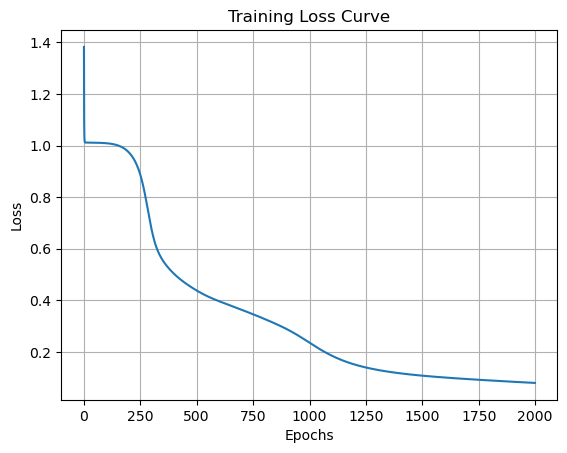

In [533]:
# Learning curve plot (cost vs epochs)
plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.grid(True)
plt.show()